# 02. Tạo đặc trưng và nhãn

## Đọc dữ liệu

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as sp_stats

raw = pd.read_csv("../data/raw/VN30_2016_2025.csv", parse_dates=["date"])
raw = raw.sort_values("date").set_index("date")
print(raw.shape)
raw.head()

(2498, 5)


,open,high,low,close,volume
date,,,,,
2016-01-04,593.31,594.68,587.94,589.91,34556428
2016-01-05,586.93,589.65,583.06,583.62,38365208
2016-01-06,582.81,589.97,582.81,589.97,34673328
2016-01-07,589.12,589.12,577.19,582.30,53139348
2016-01-08,578.97,579.97,571.96,575.96,49590708


## Lợi suất (return) 
$$
r_t = \ln\left(\frac{C_t}{C_{t-1}}\right)
$$

- $r_t$: Lợi suất logarit (Log Return) tại thời điểm $t$.
- $t$: Chỉ số thời gian hiện tại, ví dụ ngày giao dịch hôm nay.
- $C_t$: Giá đóng cửa (Closing Price) tại thời điểm $t$.
- $C_{t-1}$: Giá đóng cửa tại thời điểm ngay trước $t$, thường là phiên giao dịch trước đó.
- $\ln$: Logarit tự nhiên (Natural Logarithm), có cơ số $e \approx 2.71828$.
- $\frac{C_t}{C_{t-1}}$: Tỷ lệ giữa giá đóng cửa hiện tại và giá đóng cửa của phiên trước.

In [43]:
close = raw["close"]
r = np.log(close).diff()

stats = r.describe()

print("THỐNG KÊ MÔ TẢ LOG RETURN")
print("-" * 55)

print(f"count : {stats['count']:.0f} - Số lượng Log Return hợp lệ")
print(f"mean  : {stats['mean']:.6f} - Log Return trung bình ({stats['mean'] * 100:.4f}%)")
print(f"std   : {stats['std']:.6f} - Độ lệch chuẩn, đo mức độ biến động ({stats['std'] * 100:.4f}%)")
print(f"min   : {stats['min']:.6f} - Log Return thấp nhất ({stats['min'] * 100:.4f}%)")
print(f"25%   : {stats['25%']:.6f} - Phân vị 25% (Q1)")
print(f"50%   : {stats['50%']:.6f} - Trung vị (Median)")
print(f"75%   : {stats['75%']:.6f} - Phân vị 75% (Q3)")
print(f"max   : {stats['max']:.6f} - Log Return cao nhất ({stats['max'] * 100:.4f}%)")

THỐNG KÊ MÔ TẢ LOG RETURN
-------------------------------------------------------
count : 2497 - Số lượng Log Return hợp lệ
mean  : 0.000495 - Log Return trung bình (0.0495%)
std   : 0.012399 - Độ lệch chuẩn, đo mức độ biến động (1.2399%)
min   : -0.070522 - Log Return thấp nhất (-7.0522%)
25%   : -0.004482 - Phân vị 25% (Q1)
50%   : 0.001309 - Trung vị (Median)
75%   : 0.006757 - Phân vị 75% (Q3)
max   : 0.066700 - Log Return cao nhất (6.6700%)


## Hàm RSI

In [44]:
def rsi(close, n=14):
    delta = close.diff()  # Mức thay đổi giá giữa hai phiên liên tiếp

    gain = delta.clip(lower=0).ewm(alpha=1 / n, adjust=False).mean()  # Trung bình mức tăng
    loss = (-delta.clip(upper=0)).ewm(alpha=1 / n, adjust=False).mean()  # Trung bình mức giảm

    rs = gain / loss.replace(0, np.nan)  # Tỷ lệ giữa mức tăng và mức giảm trung bình
    return 100 - 100 / (1 + rs)  # Tính chỉ số RSI


# Tính RSI
rsi_values = rsi(close, n=14)

# Thống kê và giải thích từng tham số
stats = rsi_values.describe()

print("THỐNG KÊ CHỈ SỐ RSI (RELATIVE STRENGTH INDEX)")
print("=" * 75)

print(f"count : {stats['count']:.0f} - Số lượng giá trị RSI hợp lệ")
print(f"mean  : {stats['mean']:.4f} - RSI trung bình của toàn bộ dữ liệu")
print(f"std   : {stats['std']:.4f} - Độ lệch chuẩn, đo mức độ phân tán của RSI")
print(f"min   : {stats['min']:.4f} - Giá trị RSI thấp nhất, thể hiện mức động lượng giảm mạnh nhất")
print(f"25%   : {stats['25%']:.4f} - Phân vị 25%: 25% giá trị RSI nhỏ hơn hoặc bằng mức này")
print(f"50%   : {stats['50%']:.4f} - Trung vị RSI: 50% giá trị RSI nhỏ hơn hoặc bằng mức này")
print(f"75%   : {stats['75%']:.4f} - Phân vị 75%: 75% giá trị RSI nhỏ hơn hoặc bằng mức này")
print(f"max   : {stats['max']:.4f} - Giá trị RSI cao nhất, thể hiện mức động lượng tăng mạnh nhất")

print("\nRSI TẠI PHIÊN GẦN NHẤT")
print("=" * 75)

latest_rsi = rsi_values.dropna().iloc[-1]
print(f"RSI hiện tại: {latest_rsi:.2f} - Chỉ số động lượng tại phiên gần nhất")

if latest_rsi >= 70:
    print("Nhận xét: RSI >= 70 - Vùng thường được xem là quá mua (Overbought).")
elif latest_rsi <= 30:
    print("Nhận xét: RSI <= 30 - Vùng thường được xem là quá bán (Oversold).")
else:
    print("Nhận xét: RSI nằm trong vùng trung tính (30-70).")

THỐNG KÊ CHỈ SỐ RSI (RELATIVE STRENGTH INDEX)
count : 2497 - Số lượng giá trị RSI hợp lệ
mean  : 54.3496 - RSI trung bình của toàn bộ dữ liệu
std   : 13.9544 - Độ lệch chuẩn, đo mức độ phân tán của RSI
min   : 0.0000 - Giá trị RSI thấp nhất, thể hiện mức động lượng giảm mạnh nhất
25%   : 45.2953 - Phân vị 25%: 25% giá trị RSI nhỏ hơn hoặc bằng mức này
50%   : 54.6175 - Trung vị RSI: 50% giá trị RSI nhỏ hơn hoặc bằng mức này
75%   : 64.2410 - Phân vị 75%: 75% giá trị RSI nhỏ hơn hoặc bằng mức này
max   : 91.6347 - Giá trị RSI cao nhất, thể hiện mức động lượng tăng mạnh nhất

RSI TẠI PHIÊN GẦN NHẤT
RSI hiện tại: 63.59 - Chỉ số động lượng tại phiên gần nhất
Nhận xét: RSI nằm trong vùng trung tính (30-70).


## Tạo 13 đặc trưng

In [45]:
FEATURES = [
    "r_1", "r_2", "r_3", "r_4", "r_5",
    "ma5_gap", "ma20_gap", "mom10", "rsi14",
    "vol10", "hl_range", "oc_ret", "vol_chg"
]

data = pd.DataFrame(index=raw.index)

# 1–5. Log Return của 5 phiên gần nhất
for k in range(1, 6):
    data[f"r_{k}"] = r.shift(k - 1)

# 6. Giá hiện tại lệch bao nhiêu so với trung bình 5 phiên
data["ma5_gap"] = close / close.rolling(5).mean() - 1

# 7. Giá hiện tại lệch bao nhiêu so với trung bình 20 phiên
data["ma20_gap"] = close / close.rolling(20).mean() - 1

# 8. Động lượng giá trong 10 phiên
data["mom10"] = close / close.shift(10) - 1

# 9. RSI chuẩn hóa về khoảng [-0.5, 0.5]
data["rsi14"] = rsi(close) / 100 - 0.5

# 10. Độ biến động Log Return trong 10 phiên
data["vol10"] = r.rolling(10).std()

# 11. Biên độ giá cao nhất – thấp nhất trong phiên
data["hl_range"] = (raw["high"] - raw["low"]) / close

# 12. Tỷ suất thay đổi từ giá mở cửa đến giá đóng cửa
data["oc_ret"] = (close - raw["open"]) / raw["open"]

# 13. Khối lượng giao dịch so với trung bình 20 phiên, dùng log
data["vol_chg"] = np.log(
    raw["volume"] / raw["volume"].rolling(20).mean()
)

# In ý nghĩa từng đặc trưng
feature_meanings = {
    "r_1": "Log Return phiên hiện tại (t)",
    "r_2": "Log Return phiên trước (t-1)",
    "r_3": "Log Return cách đây 2 phiên (t-2)",
    "r_4": "Log Return cách đây 3 phiên (t-3)",
    "r_5": "Log Return cách đây 4 phiên (t-4)",
    "ma5_gap": "Mức chênh lệch tương đối giữa giá đóng cửa và trung bình 5 phiên",
    "ma20_gap": "Mức chênh lệch tương đối giữa giá đóng cửa và trung bình 20 phiên",
    "mom10": "Tỷ suất thay đổi giá đóng cửa so với 10 phiên trước",
    "rsi14": "RSI 14 phiên đã chuẩn hóa về khoảng [-0.5, 0.5]",
    "vol10": "Độ lệch chuẩn Log Return trong 10 phiên gần nhất",
    "hl_range": "Biên độ High-Low trong phiên, chia cho giá đóng cửa",
    "oc_ret": "Tỷ suất thay đổi từ giá mở cửa đến giá đóng cửa",
    "vol_chg": "Log tỷ lệ khối lượng hiện tại so với trung bình 20 phiên"
}

print("DANH SÁCH 13 ĐẶC TRƯNG (FEATURES)")
print("=" * 100)

for i, feature in enumerate(FEATURES, start=1):
    print(f"{i:2}. {feature:10} | {feature_meanings[feature]}")

print("\n5 DÒNG DỮ LIỆU MẪU")
print("=" * 100)
print(data[FEATURES].head())

print("\nTHỐNG KÊ MÔ TẢ 13 ĐẶC TRƯNG")
print("=" * 100)
print(data[FEATURES].describe().round(6))

print("\nSỐ GIÁ TRỊ THIẾU CỦA TỪNG ĐẶC TRƯNG")
print("=" * 100)
print(data[FEATURES].isna().sum())

DANH SÁCH 13 ĐẶC TRƯNG (FEATURES)
 1. r_1        | Log Return phiên hiện tại (t)
 2. r_2        | Log Return phiên trước (t-1)
 3. r_3        | Log Return cách đây 2 phiên (t-2)
 4. r_4        | Log Return cách đây 3 phiên (t-3)
 5. r_5        | Log Return cách đây 4 phiên (t-4)
 6. ma5_gap    | Mức chênh lệch tương đối giữa giá đóng cửa và trung bình 5 phiên
 7. ma20_gap   | Mức chênh lệch tương đối giữa giá đóng cửa và trung bình 20 phiên
 8. mom10      | Tỷ suất thay đổi giá đóng cửa so với 10 phiên trước
 9. rsi14      | RSI 14 phiên đã chuẩn hóa về khoảng [-0.5, 0.5]
10. vol10      | Độ lệch chuẩn Log Return trong 10 phiên gần nhất
11. hl_range   | Biên độ High-Low trong phiên, chia cho giá đóng cửa
12. oc_ret     | Tỷ suất thay đổi từ giá mở cửa đến giá đóng cửa
13. vol_chg    | Log tỷ lệ khối lượng hiện tại so với trung bình 20 phiên

5 DÒNG DỮ LIỆU MẪU
                 r_1       r_2       r_3      r_4  r_5   ma5_gap  ma20_gap  \
date                                             

## Nhãn và làm sạch

In [46]:
data["r_next"] = r.shift(-1)                                   # return phiên mai (để phân tích, không làm đặc trưng)
data["y"] = np.where(close.shift(-1) > close, 1, -1)           # +1 = Tăng, -1 = Giảm
data = data.iloc[:-1]        # phiên cuối cùng chưa biết ngày mai
data = data.dropna()         # 20 phiên đầu thiếu cửa sổ rolling
data.to_csv("../data/process/vn30_features.csv")
print(data.shape) # 2.478 phiên, 13 đặc trưng + r_next + y

(2478, 15)


## Chia train/test và tỷ lệ Tăng

In [47]:
train = data.loc[:"2022"]
test = data.loc["2023":]
split = pd.DataFrame({"Tập": ["Train 2016-2022", "Test 2023-2025"],
                      "Số phiên": [len(train), len(test)],
                      "Tỷ lệ Tăng": [(train["y"] == 1).mean(), (test["y"] == 1).mean()]})
split.to_csv("../reports/tables/split.csv", index=False)
split

,Tập,Số phiên,Tỷ lệ Tăng
0,Train 2016-2022,1731,0.555748
1,Test 2023-2025,747,0.578313


## Các đặc điểm thống kê

In [48]:
info = pd.Series({
    "excess kurtosis": sp_stats.kurtosis(data["r_1"]),
    "skewness": sp_stats.skew(data["r_1"]),
    "% phiên |r_next| < 0.2%": (data["r_next"].abs() < 0.002).mean() * 100,
    "% phiên |r| > 3 độ lệch chuẩn": (np.abs(data["r_1"] - data["r_1"].mean()) > 3 * data["r_1"].std()).mean() * 100,
})
info.round(3).to_csv("../reports/tables/data_stats.csv")
corr = data[FEATURES].corrwith(data["r_next"]).round(3)
corr.to_csv("../reports/tables/feature_corr.csv")
print(info.round(3)); corr


excess kurtosis                   4.950
skewness                         -0.872
% phiên |r_next| < 0.2%          19.572
% phiên |r| > 3 độ lệch chuẩn     2.220
dtype: float64


r_1         0.041
r_2         0.025
r_3        -0.009
r_4        -0.017
r_5         0.032
ma5_gap     0.037
ma20_gap    0.021
mom10       0.022
rsi14       0.040
vol10       0.024
hl_range    0.027
oc_ret      0.027
vol_chg     0.004
dtype: float64

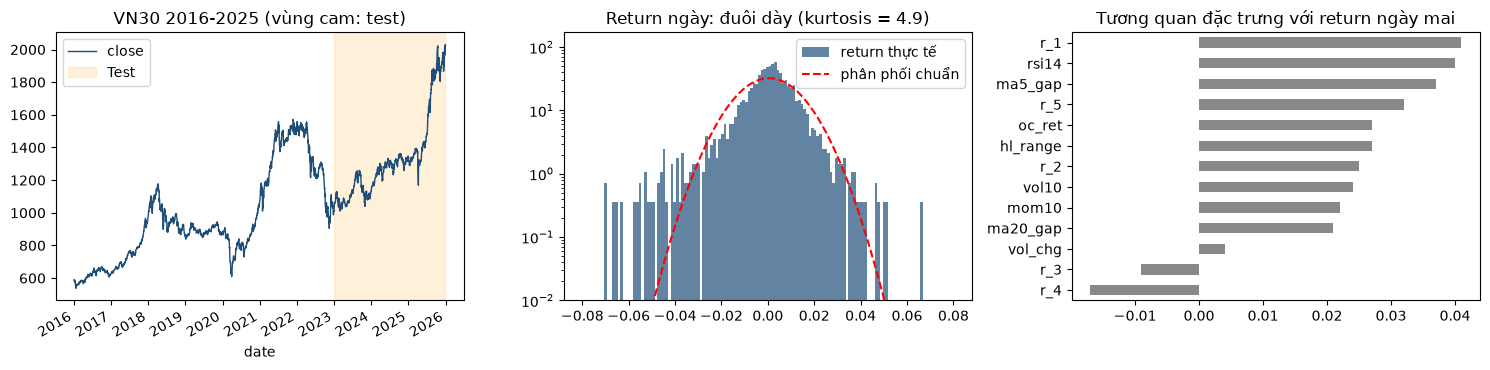

In [49]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
raw["close"].plot(ax=ax[0], color="#1f4e79", lw=1)
ax[0].axvspan(pd.Timestamp("2023-01-01"), raw.index[-1], color="orange", alpha=.15, label="Test")
ax[0].set_title("VN30 2016-2025 (vùng cam: test)"); ax[0].legend()
x = np.linspace(-0.08, 0.08, 300)
ax[1].hist(data["r_1"], bins=120, density=True, color="#1f4e79", alpha=.7, label="return thực tế")
ax[1].plot(x, sp_stats.norm.pdf(x, data["r_1"].mean(), data["r_1"].std()), "r--", label="phân phối chuẩn")
ax[1].set_yscale("log"); ax[1].set_ylim(1e-2, None); ax[1].legend()
ax[1].set_title(f"Return ngày: đuôi dày (kurtosis = {sp_stats.kurtosis(data['r_1']):.1f})")
corr.sort_values().plot.barh(ax=ax[2], color="#888")
ax[2].set_title("Tương quan đặc trưng với return ngày mai")
plt.tight_layout()
fig.savefig("../reports/figures/fig_data_overview.png", dpi=150, bbox_inches="tight")